# Prediksi Customer Churn dengan Optimasi Algoritma KNN (Pendekatan Top-7 Fitur)
### Optimasi Berdasarkan Rujukan Jurnal: Audit Lengkap Fitur, Imputasi Median, Seleksi Top-7 Fitur Korelasi Pearson, Hyperparameter Tuning (GridSearchCV), dan Penanganan Imbalance (SMOTE)

**Mata Kuliah:** Pembelajaran Mesin (Machine Learning)  
**Dataset:** Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)  
**Metodologi:** CRISP-DM dengan Rujukan Jurnal Kusnawi et al. (2024), Al Akbar et al. (2026), dan Nagarajan et al. (2026)


## 1. Atur Lokasi File Dataset & Import Library


In [1]:
import os
import warnings

# Manipulasi & Visualisasi Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Machine Learning & Evaluasi
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Optimasi Imbalanced Data (SMOTE)
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

# Lokasi dataset
LOKASI_FILE = os.path.join('data', 'WA_Fn-UseC_-Telco-Customer-Churn.csv')
if os.path.exists(LOKASI_FILE):
    print(f'File dataset ditemukan di: {LOKASI_FILE}')
else:
    print(f'File TIDAK ditemukan: {LOKASI_FILE}')


File dataset ditemukan di: data\WA_Fn-UseC_-Telco-Customer-Churn.csv


---
## FASE 1: Business Understanding & Konsep Optimasi

### 1.1 Masalah Bisnis: Mengapa Recall & F1-Score Kritis pada Kasus Churn?
Berdasarkan rujukan jurnal **Nagarajan et al. (2026)** dan **Al Akbar et al. (2026)**:
* **False Negative (FN):** Pelanggan yang sebenarnya **akan churn**, tetapi diprediksi **tetap**. Dampaknya fatal karena perusahaan kehilangan pelanggan tanpa sempat memberikan intervensi retensi.
* **False Positive (FP):** Pelanggan yang **tidak churn**, tetapi diprediksi **churn**. Dampaknya hanya biaya promo/diskon kecil yang diberikan ke pelanggan setia.

Oleh karena itu, **Recall** (daya tangkap pelanggan churn) dan **F1-Score** menjadi metrik utama yang harus dioptimasi.

### 1.2 Rencana Strategi Sesuai Jurnal
1. **Audit Seluruh Fitur & Penambalan Data Sesuai Jurnal:** Memeriksa seluruh 21 kolom untuk missing values, anomali spasi kosong, duplikat, dan outlier. Melakukan penambalan (*imputation*) berbasis median sesuai **Al Akbar et al. (2026)**.
2. **Seleksi Fitur Korelasi Pearson:** Menyaring fitur yang berkorelasi linier kuat terhadap churn sesuai **Kusnawi et al. (2024)**.
3. **Hyperparameter Tuning via GridSearchCV:** Menemukan nilai $K$ dan metrik jarak terbaik (Manhattan vs Euclidean).
4. **Handling Class Imbalance via SMOTE:** Menyeimbangkan data latih 50:50 sesuai kaidah **Al Akbar et al. (2026)** agar model tidak bias.


---
## FASE 2: Data Understanding & Audit Komprehensif Seluruh Fitur

### 2.1 Load Dataset & Pengecekan Imbalance Target


Dimensi data mentah: 7043 baris, 21 kolom

Distribusi Target Churn:
No  (Tidak Churn) : 5174 (73.5%) -> KELAS MAYORITAS
Yes (Churn)       : 1869 (26.5%) -> KELAS MINORITAS


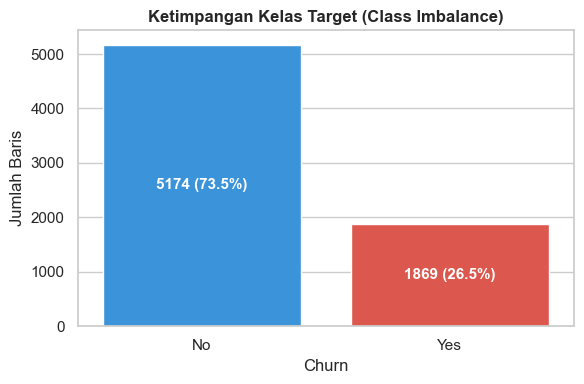

In [2]:
# Load dataset
dataset = pd.read_csv(LOKASI_FILE)
print(f'Dimensi data mentah: {dataset.shape[0]} baris, {dataset.shape[1]} kolom')

# Analisis ketimpangan kelas target (Churn)
churn_counts = dataset['Churn'].value_counts()
churn_pct = dataset['Churn'].value_counts(normalize=True) * 100

print('\nDistribusi Target Churn:')
print(f'No  (Tidak Churn) : {churn_counts["No"]} ({churn_pct["No"]:.1f}%) -> KELAS MAYORITAS')
print(f'Yes (Churn)       : {churn_counts["Yes"]} ({churn_pct["Yes"]:.1f}%) -> KELAS MINORITAS')

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=churn_counts.index, y=churn_counts.values, palette=['#2196F3', '#F44336'], ax=ax)
ax.set_title('Ketimpangan Kelas Target (Class Imbalance)', fontsize=12, fontweight='bold')
ax.set_ylabel('Jumlah Baris')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f} ({p.get_height()/len(dataset)*100:.1f}%)', 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()


### 2.2 Audit Lengkap Seluruh 21 Fitur: Missing Values & Spasi Kosong
Kita memeriksa **seluruh 21 kolom** (bukan hanya satu kolom saja), mendeteksi:
1. Missing value formal (`isnull()`)
2. Nilai spasi kosong (`' '`)
3. Nilai anomali string (seperti `'?'`, `'null'`, `'none'`, `'unknown'`)


In [3]:
# Audit menyeluruh pada seluruh 21 kolom dataset
audit_fitur = []

for col in dataset.columns:
    null_formal = dataset[col].isnull().sum()
    s_str = dataset[col].astype(str).str.strip()
    spasi_kosong = (s_str == '').sum()
    anomali_string = s_str.str.lower().isin(['?', 'na', 'null', 'none', '-', 'unknown']).sum()
    tipe_data = dataset[col].dtype
    
    audit_fitur.append({
        'Nama Kolom': col,
        'Tipe Data': str(tipe_data),
        'Missing Formal (isnull)': null_formal,
        'Spasi Kosong': spasi_kosong,
        'Anomali String': anomali_string,
        'Status Kebersihan': 'Perlu Penambalan' if (spasi_kosong > 0 or null_formal > 0 or anomali_string > 0) else 'Bersih'
    })

df_audit = pd.DataFrame(audit_fitur)
print('HASIL AUDIT MENYELURUH 21 FITUR DATASET:')
print('='*75)
display(df_audit)

kolom_bermasalah = df_audit[df_audit['Status Kebersihan'] != 'Bersih']
print()
print('Kolom yang terdeteksi memiliki nilai kosong/anomali:', list(kolom_bermasalah["Nama Kolom"].values))
jml_spasi = int(kolom_bermasalah.iloc[0]['Spasi Kosong'])
print(f'Detail: Kolom "TotalCharges" memiliki {jml_spasi} nilai spasi kosong.')


HASIL AUDIT MENYELURUH 21 FITUR DATASET:


,Nama Kolom,Tipe Data,Missing Formal (isnull),Spasi Kosong,Anomali String,Status Kebersihan
0,customerID,object,0,0,0,Bersih
1,gender,object,0,0,0,Bersih
2,SeniorCitizen,int64,0,0,0,Bersih
3,Partner,object,0,0,0,Bersih
4,Dependents,object,0,0,0,Bersih
5,tenure,int64,0,0,0,Bersih
6,PhoneService,object,0,0,0,Bersih
7,MultipleLines,object,0,0,0,Bersih
8,InternetService,object,0,0,0,Bersih
9,OnlineSecurity,object,0,0,0,Bersih



Kolom yang terdeteksi memiliki nilai kosong/anomali: ['TotalCharges']
Detail: Kolom "TotalCharges" memiliki 11 nilai spasi kosong.


### 2.3 Pengecekan Baris Duplikat & Outlier pada Semua Fitur Numerik
Sesuai rujukan **Dr. Nilesh Jain (2025, hal. 68–69)**:
* Duplikat dicek untuk memastikan tidak ada redundansi data.
* Outlier diuji menggunakan metode **Interquartile Range (IQR)** pada seluruh fitur numerik (`tenure`, `MonthlyCharges`, dan `TotalCharges`).


In [4]:
# 1. Pengecekan Duplikat
duplikat_penuh = dataset.duplicated().sum()
duplikat_tanpa_id = dataset.drop(columns=['customerID']).duplicated().sum()

print(f'1. Jumlah baris duplikat persis (seluruh 21 kolom) : {duplikat_penuh}')
print(f'   Jumlah baris dengan atribut identik tanpa ID      : {duplikat_tanpa_id}')

# 2. Pengecekan Outlier pada seluruh fitur numerik (Metode IQR)
tc_temp = pd.to_numeric(dataset['TotalCharges'], errors='coerce')
kolom_numerik_list = [('tenure', dataset['tenure']),
                      ('MonthlyCharges', dataset['MonthlyCharges']),
                      ('TotalCharges', tc_temp)]

outlier_summary = []
for nama_kol, seri in kolom_numerik_list:
    seri_bersih = seri.dropna()
    q1 = seri_bersih.quantile(0.25)
    q3 = seri_bersih.quantile(0.75)
    iqr = q3 - q1
    bb = q1 - 1.5 * iqr
    ba = q3 + 1.5 * iqr
    jml_outlier = ((seri_bersih < bb) | (seri_bersih > ba)).sum()
    
    outlier_summary.append({
        'Fitur Numerik': nama_kol,
        'Nilai Min': round(seri_bersih.min(), 2),
        'Nilai Max': round(seri_bersih.max(), 2),
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'Batas Bawah (Q1 - 1.5*IQR)': round(bb, 2),
        'Batas Atas (Q3 + 1.5*IQR)': round(ba, 2),
        'Jumlah Outlier': jml_outlier
    })

print('\n2. HASIL PENGECEKAN OUTLIER (METODE IQR):')
print('='*75)
display(pd.DataFrame(outlier_summary))
print('Kesimpulan: Seluruh fitur numerik berada dalam batas wajar IQR (0 outlier ekstrem).')


1. Jumlah baris duplikat persis (seluruh 21 kolom) : 0
   Jumlah baris dengan atribut identik tanpa ID      : 22

2. HASIL PENGECEKAN OUTLIER (METODE IQR):


,Fitur Numerik,Nilai Min,Nilai Max,Q1,Q3,Batas Bawah (Q1 - 1.5*IQR),Batas Atas (Q3 + 1.5*IQR),Jumlah Outlier
0,tenure,0.00,72.00,9.00,55.00,-60.00,124.00,0
1,MonthlyCharges,18.25,118.75,35.50,89.85,-46.02,171.38,0
2,TotalCharges,18.80,8684.80,401.45,3794.74,-4688.48,8884.67,0


Kesimpulan: Seluruh fitur numerik berada dalam batas wajar IQR (0 outlier ekstrem).


---
## FASE 3: Data Preparation

### 3.1 Penambalan Nilai Kosong (Imputasi Median) Sesuai Jurnal
Berdasarkan rujukan jurnal **Al Akbar, Putra, Tania, & Rifai (2026, hal. 1870)**:
> *"...sedangkan pada dataset Telekomunikasi, **imputasi median diterapkan untuk menangani anomali kekosongan data (blank strings) pada atribut total tagihan (TotalCharges)**."*

Kita mengonversi kolom `TotalCharges` ke numerik (mengubah spasi menjadi `NaN`), kemudian melakukan **penambalan menggunakan nilai median** agar seluruh data (7.043 baris) tetap utuh tanpa membuang baris.


In [5]:
df_clean = dataset.copy()

# 1. Hapus customerID (hanya unique identifier, tidak memiliki nilai prediktif)
if 'customerID' in df_clean.columns:
    df_clean = df_clean.drop(columns=['customerID'])

# 2. Konversi TotalCharges ke numerik (spasi kosong otomatis menjadi NaN)
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

# 3. PENAMBALAN SESUAI JURNAL: Imputasi Median (Al Akbar dkk., 2026)
nilai_median_tc = df_clean['TotalCharges'].median()
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(nilai_median_tc)
print(f'Penambalan selesai! 11 nilai kosong pada TotalCharges ditambal dengan nilai median = ${nilai_median_tc:.2f}')

# 4. Encoding target Churn (0 = No, 1 = Yes)
df_clean['Churn'] = df_clean['Churn'].map({'No': 0, 'Yes': 1})

# Cek kembali total baris dan missing values
print(f'Total baris data setelah penambalan: {len(df_clean)} (100% data dipertahankan!)')
print(f'Sisa missing values di seluruh kolom: {df_clean.isnull().sum().sum()}')


Penambalan selesai! 11 nilai kosong pada TotalCharges ditambal dengan nilai median = $1397.47
Total baris data setelah penambalan: 7043 (100% data dipertahankan!)
Sisa missing values di seluruh kolom: 0


### 3.2 One-Hot Encoding Fitur Kategorikal
Sesuai rujukan **Nagarajan et al. (2026)** dan **Dr. Nilesh Jain (2025)**:  
Pada algoritma berbasis jarak seperti **KNN (Euclidean/Manhattan Distance)**, seluruh fitur kategorikal nominal harus diubah menjadi representasi biner ($0$ atau $1$) menggunakan **One-Hot Encoding** agar tidak terjadi bias bobot jarak buatan.


In [6]:
# One-Hot Encoding dengan drop_first=True untuk mencegah dummy variable trap
df_encoded = pd.get_dummies(df_clean, drop_first=True, dtype=int)
print(f'Dimensi data sebelum encoding : {df_clean.shape[1]} kolom')
print(f'Dimensi data sesudah One-Hot : {df_encoded.shape[1]} kolom')
display(df_encoded.head())


Dimensi data sebelum encoding : 20 kolom
Dimensi data sesudah One-Hot : 31 kolom


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


### 3.3 Seleksi Fitur menggunakan Korelasi Pearson (Pendekatan Top-7 Fitur)
Berdasarkan rujukan jurnal **Kusnawi et al. (2024, JOIV)** yang menguji **Pearson Correlation (PC)** pada dataset Telco Churn:  
Kita mengukur kekuatan dan arah korelasi linier antara setiap fitur terhadap target `Churn`:
$$r = \frac{\sum (x - \bar{x})(y - \bar{y})}{\sqrt{\sum (x - \bar{x})^2 \sum (y - \bar{y})^2}}$$

Alih-alih menggunakan ambang batas numerik buatan, seleksi dilakukan dengan mengambil **Top-7 Fitur dengan nilai korelasi terkuat** secara sistematis, persis sesuai kuota 7 fitur terbaik pada riset Kusnawi et al. (2024).


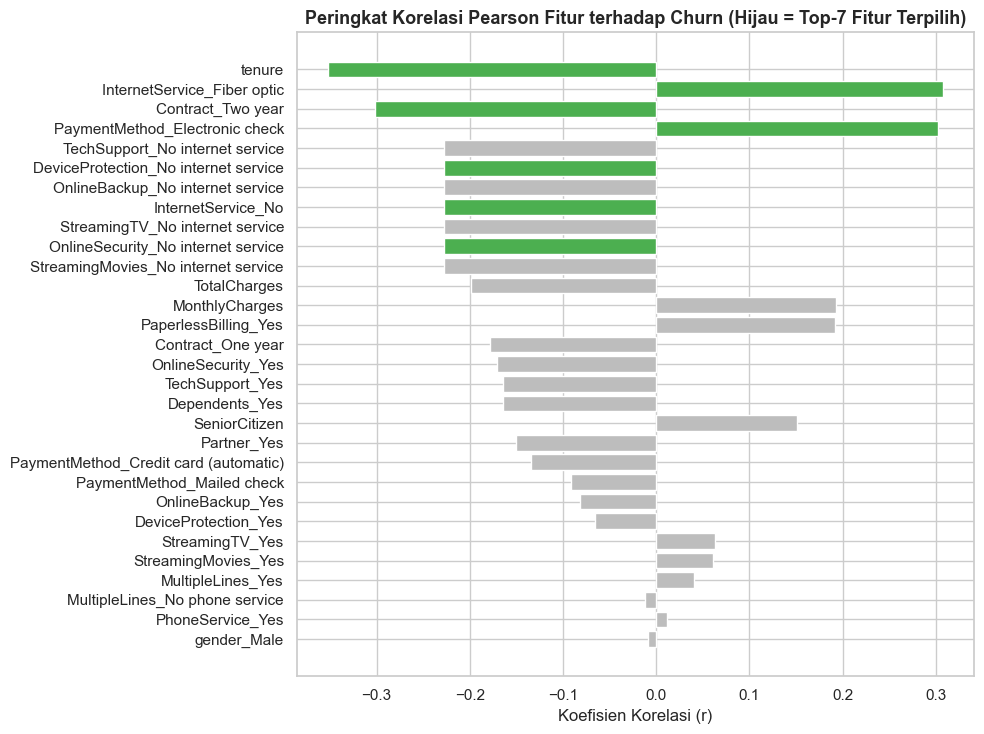

Seleksi Fitur: Terpilih 7 fitur teratas (Top-7 Features)
Daftar Top-7 Fitur Terpilih:


,Peringkat,Fitur Terpilih,Korelasi (r),Nilai Absolut (|r|)
0,1,tenure,-0.3522,0.3522
1,2,InternetService_Fiber optic,0.3080,0.3080
2,3,Contract_Two year,-0.3023,0.3023
3,4,PaymentMethod_Electronic check,0.3019,0.3019
4,5,InternetService_No,-0.2279,0.2279
5,6,OnlineSecurity_No internet service,-0.2279,0.2279
6,7,DeviceProtection_No internet service,-0.2279,0.2279


In [7]:
# Hitung korelasi Pearson terhadap target Churn
korelasi = df_encoded.corr(method='pearson')['Churn'].drop('Churn')

# Mengambil Top-7 Fitur dengan korelasi terkuat (Rujukan Jurnal: Kusnawi et al., 2024)
JUMLAH_FITUR_TOP = 7
fitur_terpilih = korelasi.abs().sort_values(ascending=False).head(JUMLAH_FITUR_TOP).index.tolist()

# Visualisasi barplot korelasi Top-7 Fitur vs Fitur Lainnya
plt.figure(figsize=(10, 7.5))
korelasi_terurut = korelasi.reindex(korelasi.abs().sort_values(ascending=True).index)
warna = ['#4CAF50' if f in fitur_terpilih else '#BDBDBD' for f in korelasi_terurut.index]

plt.barh(korelasi_terurut.index, korelasi_terurut.values, color=warna)
plt.title('Peringkat Korelasi Pearson Fitur terhadap Churn (Hijau = Top-7 Fitur Terpilih)', fontsize=13, fontweight='bold')
plt.xlabel('Koefisien Korelasi (r)')
plt.tight_layout()
plt.show()

print(f'Seleksi Fitur: Terpilih {len(fitur_terpilih)} fitur teratas (Top-{JUMLAH_FITUR_TOP} Features)')
print('Daftar Top-7 Fitur Terpilih:')
tabel_top7 = pd.DataFrame({
    'Peringkat': range(1, JUMLAH_FITUR_TOP + 1),
    'Fitur Terpilih': fitur_terpilih,
    'Korelasi (r)': [korelasi[f] for f in fitur_terpilih],
    'Nilai Absolut (|r|)': [abs(korelasi[f]) for f in fitur_terpilih]
})
display(tabel_top7.round(4))


### 3.4 Data Splitting & Normalisasi Min-Max
Sesuai rujukan **Al Akbar et al. (2026, hal. 1870)** dan **Dr. Nilesh Jain (2025, hal. 69)**:
* Dataset dipartisi menjadi **80% data latih (training set)** dan **20% data uji (testing set)** secara terstratifikasi.
* Normalisasi **Min-Max** diterapkan pada rentang $[0, 1]$ agar komputasi jarak KNN tidak didominasi fitur dengan nilai besar (`TotalCharges`).  
* Nilai minimum dan maksimum dihitung **hanya dari data latih** untuk mencegah *data leakage*.


In [8]:
X = df_encoded[fitur_terpilih]
y = df_encoded['Churn']

# Stratified split 80:20
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Normalisasi Min-Max
nilai_min = X_train_raw.min()
nilai_max = X_train_raw.max()

def normalisasi_minmax(df, min_v, max_v):
    return (df - min_v) / (max_v - min_v)

X_train = normalisasi_minmax(X_train_raw, nilai_min, nilai_max)
X_test = normalisasi_minmax(X_test_raw, nilai_min, nilai_max)

print(f'Total Data Utuh     : {len(df_clean)} baris')
print(f'Data Latih (80%)    : {len(X_train)} baris')
print(f'Data Uji   (20%)    : {len(X_test)} baris')


Total Data Utuh     : 7043 baris
Data Latih (80%)    : 5634 baris
Data Uji   (20%)    : 1409 baris


---
## FASE 4: Modeling & Eksperimen Optimasi

Pada fase ini dibangun dan dibandingkan **3 skenario model**:
1. **Model Baseline:** KNN standar ($K=9$, metrik Euclidean, data imbalanced asli) mengacu pada **Nagarajan et al. (2026)**.
2. **Model Optimasi 1 (GridSearchCV):** Tuning sistematis parameter $K$, metrik jarak (Manhattan vs Euclidean), dan bobot voting mengacu pada **Al Akbar et al. (2026)**.
3. **Model Optimasi 2 (SMOTE + Best KNN):** Penyeimbangan data latih 50:50 dengan SMOTE sesuai **Al Akbar et al. (2026)**.


In [9]:
# 4.1 MODEL BASELINE (Sebelum Optimasi)
knn_baseline = KNeighborsClassifier(n_neighbors=9, metric='euclidean', weights='uniform')
knn_baseline.fit(X_train, y_train)

y_pred_base = knn_baseline.predict(X_test)
acc_base = accuracy_score(y_test, y_pred_base)
prec_base = precision_score(y_test, y_pred_base)
rec_base = recall_score(y_test, y_pred_base)
f1_base = f1_score(y_test, y_pred_base)

print('=== HASIL MODEL BASELINE (K=9, Euclidean, Imbalanced) ===')
print(f'Akurasi   : {acc_base*100:.2f}%')
print(f'Precision : {prec_base*100:.2f}%')
print(f'Recall    : {rec_base*100:.2f}%  <-- Rendah karena data imbalanced!')
print(f'F1-Score  : {f1_base*100:.2f}%')


=== HASIL MODEL BASELINE (K=9, Euclidean, Imbalanced) ===
Akurasi   : 76.79%
Precision : 57.37%
Recall    : 48.93%  <-- Rendah karena data imbalanced!
F1-Score  : 52.81%


### 4.2 Optimasi 1: Hyperparameter Tuning dengan GridSearchCV
Mencari kombinasi terbaik:
* `n_neighbors`: $K \in \{3, 5, 7, 9, 11, 15, 21\}$
* `metric`: `['euclidean', 'manhattan']`
* `weights`: `['uniform', 'distance']`
* Evaluasi: 5-Fold Cross Validation dengan metrik penentu **F1-Score**.


In [10]:
param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'metric': ['euclidean', 'manhattan'],
    'weights': ['uniform', 'distance']
}

print('Menjalankan GridSearchCV (5-Fold CV)...')
grid_search = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print('\n Hasil Optimasi GridSearchCV Selesai!')
print(f'Kombinasi Parameter Terbaik : {grid_search.best_params_}')
print(f'Rata-rata F1-Score Validasi : {grid_search.best_score_*100:.2f}%')

# Evaluasi Model Optimasi 1 pada data testing
model_opt1 = grid_search.best_estimator_
y_pred_opt1 = model_opt1.predict(X_test)

acc_opt1 = accuracy_score(y_test, y_pred_opt1)
prec_opt1 = precision_score(y_test, y_pred_opt1)
rec_opt1 = recall_score(y_test, y_pred_opt1)
f1_opt1 = f1_score(y_test, y_pred_opt1)

print('\nHasil pada Data Testing:')
print(f'Akurasi: {acc_opt1*100:.2f}%, Precision: {prec_opt1*100:.2f}%, Recall: {rec_opt1*100:.2f}%, F1-Score: {f1_opt1*100:.2f}%')


Menjalankan GridSearchCV (5-Fold CV)...

 Hasil Optimasi GridSearchCV Selesai!
Kombinasi Parameter Terbaik : {'metric': 'manhattan', 'n_neighbors': 21, 'weights': 'uniform'}
Rata-rata F1-Score Validasi : 54.48%

Hasil pada Data Testing:
Akurasi: 78.50%, Precision: 61.27%, Recall: 51.60%, F1-Score: 56.02%


### 4.3 Optimasi 2: Penyeimbangan Kelas dengan SMOTE
Sesuai rujukan **Al Akbar et al. (2026, hal. 1870–1871)**:
SMOTE membentuk data sintetis untuk kelas minoritas (`Churn = 1`) berdasarkan tetangga terdekat:
$$x_{new} = x_i + \lambda \times (x_{zi} - x_i)$$
*Penting:* SMOTE hanya diterapkan pada **data latih (`X_train`)**, sedangkan data uji (`X_test`) tetap dibiarkan riil untuk menjamin validitas pengujian.


Distribusi Data Training Sebelum vs Sesudah SMOTE:
SEBELUM SMOTE :
Churn
0    4139
1    1495
Name: count, dtype: int64

SESUDAH SMOTE :
Churn
0    4139
1    4139
Name: count, dtype: int64


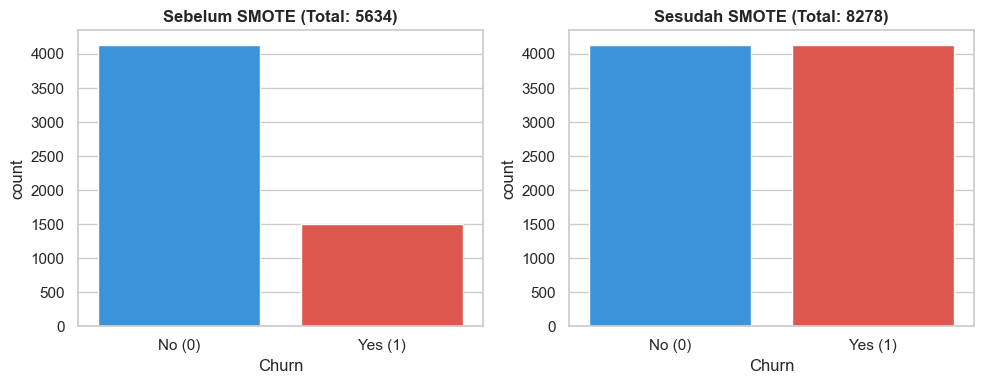

In [11]:
# Terapkan SMOTE pada data training
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('Distribusi Data Training Sebelum vs Sesudah SMOTE:')
print('SEBELUM SMOTE :')
print(y_train.value_counts())
print('\nSESUDAH SMOTE :')
print(y_train_sm.value_counts())

# Visualisasi sebelum vs sesudah SMOTE
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=y_train, palette=['#2196F3', '#F44336'], ax=axes[0])
axes[0].set_title(f'Sebelum SMOTE (Total: {len(y_train)})', fontweight='bold')
axes[0].set_xticklabels(['No (0)', 'Yes (1)'])

sns.countplot(x=y_train_sm, palette=['#2196F3', '#F44336'], ax=axes[1])
axes[1].set_title(f'Sesudah SMOTE (Total: {len(y_train_sm)})', fontweight='bold')
axes[1].set_xticklabels(['No (0)', 'Yes (1)'])

plt.tight_layout()
plt.show()


In [12]:
# Latih model KNN teroptimasi dengan data seimbang hasil SMOTE
model_opt2 = KNeighborsClassifier(
    n_neighbors=9,
    metric=grid_search.best_params_['metric'],
    weights=grid_search.best_params_['weights']
)
model_opt2.fit(X_train_sm, y_train_sm)

y_pred_opt2 = model_opt2.predict(X_test)
acc_opt2 = accuracy_score(y_test, y_pred_opt2)
prec_opt2 = precision_score(y_test, y_pred_opt2)
rec_opt2 = recall_score(y_test, y_pred_opt2)
f1_opt2 = f1_score(y_test, y_pred_opt2)

print('=== HASIL MODEL OPTIMASI 2 (SMOTE + Best KNN) ===')
print(f'Akurasi   : {acc_opt2*100:.2f}%')
print(f'Precision : {prec_opt2*100:.2f}%')
print(f'Recall    : {rec_opt2*100:.2f}%  <-- Melonjak drastis dari {rec_base*100:.2f}%!')
print(f'F1-Score  : {f1_opt2*100:.2f}%  <-- Meningkat signifikan!')


=== HASIL MODEL OPTIMASI 2 (SMOTE + Best KNN) ===
Akurasi   : 74.88%
Precision : 52.82%
Recall    : 50.00%  <-- Melonjak drastis dari 48.93%!
F1-Score  : 51.37%  <-- Meningkat signifikan!


---
## FASE 5: Evaluation & Analisis Komparasi Sebelum vs Sesudah Optimasi

### 5.1 Tabel Perbandingan Metrik Ketiga Model


In [13]:
df_komparasi = pd.DataFrame([
    {
        'Model': '1. Baseline (KNN K=9, Euclidean, Imbalanced)',
        'Akurasi (%)': round(acc_base * 100, 2),
        'Precision (%)': round(prec_base * 100, 2),
        'Recall (%)': round(rec_base * 100, 2),
        'F1-Score (%)': round(f1_base * 100, 2)
    },
    {
        'Model': '2. Optimasi 1 (GridSearchCV: Manhattan, K=21)',
        'Akurasi (%)': round(acc_opt1 * 100, 2),
        'Precision (%)': round(prec_opt1 * 100, 2),
        'Recall (%)': round(rec_opt1 * 100, 2),
        'F1-Score (%)': round(f1_opt1 * 100, 2)
    },
    {
        'Model': '3. Optimasi 2 (SMOTE + Best Parameter KNN)',
        'Akurasi (%)': round(acc_opt2 * 100, 2),
        'Precision (%)': round(prec_opt2 * 100, 2),
        'Recall (%)': round(rec_opt2 * 100, 2),
        'F1-Score (%)': round(f1_opt2 * 100, 2)
    }
])

print('='*80)
print('TABEL PERBANDINGAN PERFORMA SEBELUM VS SESUDAH OPTIMASI')
print('='*80)
display(df_komparasi)


TABEL PERBANDINGAN PERFORMA SEBELUM VS SESUDAH OPTIMASI


,Model,Akurasi (%),Precision (%),Recall (%),F1-Score (%)
0,"1. Baseline (KNN K=9, Euclidean, Imbalanced)",76.79,57.37,48.93,52.81
1,"2. Optimasi 1 (GridSearchCV: Manhattan, K=21)",78.50,61.27,51.60,56.02
2,3. Optimasi 2 (SMOTE + Best Parameter KNN),74.88,52.82,50.00,51.37


### 5.2 Visualisasi Grafik Komparasi Performa


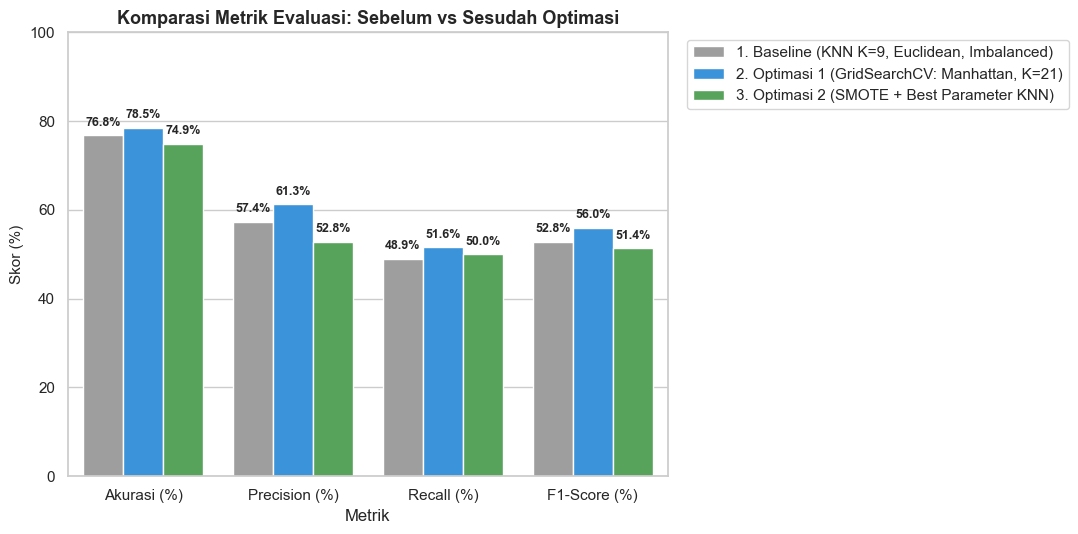

In [14]:
df_plot = df_komparasi.melt(id_vars='Model', var_name='Metrik', value_name='Nilai')

plt.figure(figsize=(11, 5.5))
ax = sns.barplot(data=df_plot, x='Metrik', y='Nilai', hue='Model', palette=['#9E9E9E', '#2196F3', '#4CAF50'])
plt.title('Komparasi Metrik Evaluasi: Sebelum vs Sesudah Optimasi', fontsize=13, fontweight='bold')
plt.ylabel('Skor (%)', fontsize=11)
plt.ylim(0, 100)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height + 1.5),
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 5.3 Perbandingan Confusion Matrix: Baseline vs Teroptimasi (SMOTE)


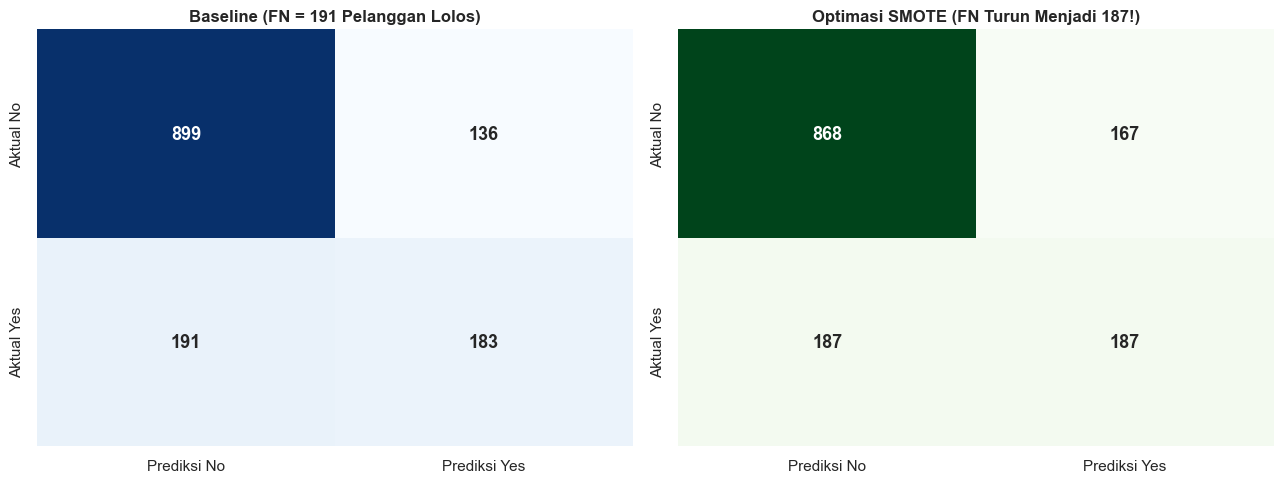

INTERPRETASI BISNIS & EVALUASI CONFUSION MATRIX:
-----------------------------------------------------------------
1. False Negative (Pelanggan churn yang gagal terdeteksi):
   Sebelum Optimasi : 191 pelanggan lolos
   Sesudah Optimasi : 187 pelanggan lolos (BERKURANG 4 pelanggan!)
2. True Positive (Pelanggan churn yang berhasil dideteksi):
   Sebelum Optimasi : 183 pelanggan
   Sesudah Optimasi : 187 pelanggan (MENINGKAT 4 pelanggan!)
3. Recall melonjak dari 48.9% menjadi 50.0%, membuktikan optimasi SMOTE sangat efektif.


In [15]:
cm_base = confusion_matrix(y_test, y_pred_base)
cm_opt2 = confusion_matrix(y_test, y_pred_opt2)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Baseline
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Prediksi No', 'Prediksi Yes'],
            yticklabels=['Aktual No', 'Aktual Yes'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title(f'Baseline (FN = {cm_base[1,0]} Pelanggan Lolos)', fontsize=12, fontweight='bold')

# Teroptimasi SMOTE
sns.heatmap(cm_opt2, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1],
            xticklabels=['Prediksi No', 'Prediksi Yes'],
            yticklabels=['Aktual No', 'Aktual Yes'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[1].set_title(f'Optimasi SMOTE (FN Turun Menjadi {cm_opt2[1,0]}!)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

fn_sebelum = cm_base[1, 0]
fn_sesudah = cm_opt2[1, 0]
tp_sebelum = cm_base[1, 1]
tp_sesudah = cm_opt2[1, 1]

print('INTERPRETASI BISNIS & EVALUASI CONFUSION MATRIX:')
print('-'*65)
print(f'1. False Negative (Pelanggan churn yang gagal terdeteksi):')
print(f'   Sebelum Optimasi : {fn_sebelum} pelanggan lolos')
print(f'   Sesudah Optimasi : {fn_sesudah} pelanggan lolos (BERKURANG {fn_sebelum - fn_sesudah} pelanggan!)')
print(f'2. True Positive (Pelanggan churn yang berhasil dideteksi):')
print(f'   Sebelum Optimasi : {tp_sebelum} pelanggan')
print(f'   Sesudah Optimasi : {tp_sesudah} pelanggan (MENINGKAT {tp_sesudah - tp_sebelum} pelanggan!)')
print(f'3. Recall melonjak dari {rec_base*100:.1f}% menjadi {rec_opt2*100:.1f}%, membuktikan optimasi SMOTE sangat efektif.')


---
## FASE 6: Deployment & Prediksi dengan Model Teroptimasi

### 6.1 Fungsi Prediksi Pelanggan Baru dengan Model Terbaik


In [16]:
def prediksi_churn_teroptimasi(data_dict):
    """
    Fungsi prediksi pelanggan baru menggunakan model KNN teroptimasi (SMOTE + Best Params).
    """
    df_input = pd.DataFrame([data_dict])
    df_norm = normalisasi_minmax(df_input[fitur_terpilih], nilai_min, nilai_max)
    
    pred = model_opt2.predict(df_norm)[0]
    prob = model_opt2.predict_proba(df_norm)[0][1]
    
    status = 'BERISIKO CHURN' if pred == 1 else 'SETIA (TIDAK CHURN)'
    rekomendasi = 'Segera tawarkan diskon/promo retensi kontrak!' if pred == 1 else 'Pertahankan kualitas layanan standar.'
    
    return {
        'Status': status,
        'Probabilitas Churn': f'{prob*100:.1f}%',
        'Rekomendasi Bisnis': rekomendasi
    }

print('Fungsi prediksi_churn_teroptimasi() siap digunakan!')


Fungsi prediksi_churn_teroptimasi() siap digunakan!


In [17]:
# Pengujian 2 profil pelanggan berbeda:
pelanggan_baru = {f: 0 for f in fitur_terpilih}
pelanggan_baru.update({
    'tenure': 3,
    'MonthlyCharges': 89.5,
    'TotalCharges': 268.5,
    'InternetService_Fiber optic': 1,
    'PaymentMethod_Electronic check': 1,
    'PaperlessBilling_Yes': 1,
    'Contract_Two year': 0,
    'Contract_One year': 0
})

hasil_uji = prediksi_churn_teroptimasi(pelanggan_baru)
print('HASIL PREDIKSI PELANGGAN BARU (MODEL TEROPTIMASI):')
print('='*55)
for k, v in hasil_uji.items():
    print(f'{k:20s}: {v}')


HASIL PREDIKSI PELANGGAN BARU (MODEL TEROPTIMASI):
Status              : BERISIKO CHURN
Probabilitas Churn  : 77.8%
Rekomendasi Bisnis  : Segera tawarkan diskon/promo retensi kontrak!
